# Normalización y estandarización de datos médicos con CRISP-DM
![logo Itq](img/ITQ.png)

**Nombre:** Freddy Daniel Guevara Villon

**Fecha** *23-11-2026*

**CRISP-DM:** metodología que organiza un proyecto de datos en fases. En esta práctica trabajamos las fases 1 (comprensión del negocio), 2 (comprensión de los datos) y 3 (preparación de los datos) hasta la normalización y la estandarización.

**Link Repositorio** https://github.com/Fguevara92/Fund_Machin_Learn_IA_Noct_26_27/blob/main/Guevara_Freddy_Practica_Datos_Medicos.ipynb

---
## Paso 1. Descarga y registro de la fuente

Los datos vienen del repositorio oficial de UCI: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

Ejecutamos las dos celdas que entrega la guía, en el mismo orden.

### Celda 1. Instalación del paquete de descarga
Instalamos `ucimlrepo`, la librería que descarga el dataset directamente desde UCI.

In [1]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


### Celda 2. Descarga y copia local
Descargamos el dataset, comprobamos que tenga más de 100 000 filas, vemos las primeras filas y el diccionario de UCI, y guardamos una copia en CSV.

In [35]:
from ucimlrepo import fetch_ucirepo

# Descargar el conjunto de datos desde UCI.
dataset = fetch_ucirepo(id=296)

# Obtener una copia de todos los datos.
df = dataset.data.original.copy()

# Verificar que cumple con el tamaño solicitado.
print("Filas y columnas:", df.shape)
assert len(df) > 100_000, "El dataset debe superar los 100 000 registros."

# Visualizar los primeros registros.
display(df.head())

# Consultar el diccionario de variables.
display(dataset.variables)

# Guardar una copia local para desarrollar la actividad.
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)

C:\Users\fguev\anaconda3\envs\fundamentos_marchine_learning\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Filas y columnas: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,None,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,None,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,None,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,None,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,None,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,None,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,None,Integer number of days between admission and d...,None,no


**Interpretación:** el dataset se descargó completo con **101 766 filas y 50 columnas** y quedó guardado como `hospitalizaciones_diabetes_original.csv`.

**Nota sobre el aviso en rojo:** al descargar aparece un `DtypeWarning` en la columna 10 (`payer_code`). No es un error. Sale porque esa columna tiene códigos de texto (como `MC` o `SP`) y también celdas vacías, que pandas guarda como números. Los datos se cargaron completos y esta columna la tratamos como categórica en la limpieza, así que el aviso no afecta el análisis.

### Importación de librerías
* **pandas**: maneja los datos como una tabla.
* **numpy**: trabaja con arreglos, cuenta ocurrencias con `np.unique` y busca posiciones con `np.where`.
* **matplotlib** y **seaborn**: dibujan los gráficos.
* **scipy.stats**: calcula los percentiles para el método de caja y bigotes (box plot), como en el Programa3.
* **preprocessing**: módulo de scikit-learn que trae `MinMaxScaler` y `StandardScaler`, como en los Programas 1 y 2.
* **SimpleImputer**: rellena valores ausentes, como en el Programa4.
* **datetime** y **sys**: nos dan la fecha de descarga y la versión de Python.

In [36]:
# Importación de librerías
import sys
from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import sklearn
from sklearn import preprocessing
from sklearn.impute import SimpleImputer

### Registro de la descarga
Anotamos **cuándo** descargamos los datos, **qué tamaño** tienen y **qué versiones** de librerías usamos, para que cualquier persona pueda repetir el trabajo.

También guardamos `df_original`, una copia que **no vamos a modificar**. Todos los cambios se hacen sobre otras copias.

In [37]:
# Copia original que no se toca en todo el notebook
df_original = df.copy()

print("Fecha de descarga:", datetime.now().strftime("%d-%m-%Y %H:%M"))
print("Fuente: UCI Machine Learning Repository, id = 296")
print("Tabla de datos: %d filas y %d columnas" % (df_original.shape[0], df_original.shape[1]))
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scipy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)

Fecha de descarga: 22-11-2026 15:20
Fuente: UCI Machine Learning Repository, id = 296
Tabla de datos: 101766 filas y 50 columnas
Python: 3.13.18
pandas: 2.3.3
numpy: 2.3.5
matplotlib: 3.11.2
seaborn: 0.13.2
scipy: 1.18.1
scikit-learn: 1.9.1


---
## Paso 2. Fase 1 de CRISP-DM: Comprensión del negocio

### ¿Cuál es el problema?
Una **readmisión** ocurre cuando un paciente que ya salió del hospital tiene que volver a internarse. En pacientes con diabetes pasa con frecuencia y es un problema porque:
* Para el **paciente** significa que su salud no quedó estable.
* Para el **hospital** significa más gastos y camas ocupadas.
* Para los **médicos y enfermeras** es una señal de que tal vez faltó seguimiento después del alta.

### ¿Quiénes están interesados?
* El equipo médico (médicos, enfermeras, especialistas en diabetes).
* La administración del hospital, que controla costos y calidad.
* Las aseguradoras que pagan la atención.
* El equipo de análisis de datos, que es el papel que tomamos en esta práctica.

### ¿Por qué explorar los datos antes de hacer un modelo?
Porque si los datos tienen errores, vacíos o variables mal entendidas, cualquier modelo que se construya después dará resultados equivocados. Primero necesitamos saber **qué hay en los datos y qué tan buenos son**, y dejar las variables numéricas en escalas comparables.

### Objetivo general
Describir la calidad y la distribución de los datos de hospitalizaciones de pacientes con diabetes y preparar siete variables numéricas en dos versiones comparables (normalizada y estandarizada), para que el equipo hospitalario tenga una base confiable antes de construir modelos.

### Preguntas de análisis
1. **P1.** ¿Cómo se reparten las hospitalizaciones entre las categorías de readmisión (`NO`, `<30`, `>30`)?
2. **P2.** ¿Qué tan completos y limpios están los datos? (faltantes, duplicados y valores atípicos)
3. **P3.** De forma descriptiva, ¿las hospitalizaciones con readmisión antes de 30 días tienen en promedio más días de estancia, más medicamentos o más hospitalizaciones previas que las que no se readmiten?

### Criterios de éxito (cosas que podemos comprobar)
| N.º | Criterio | Cómo lo comprobamos |
|---|---|---|
| C1 | Se cargan las 101 766 filas | Conteo de filas en el Paso 3 |
| C2 | Existe un diccionario de las 50 columnas | Tabla del Paso 3 |
| C3 | Cada decisión de limpieza queda registrada con filas y columnas antes y después | Registro de limpieza del Paso 4 |
| C4 | Después de limpiar siguen quedando más de 100 000 filas | Comprobación en el Paso 4 |
| C5 | Min-Max deja cada variable entre 0 y 1 | Comprobación con tolerancia en el Paso 6 |
| C6 | Z-score deja media ≈ 0 y desviación ≈ 1 | Comprobación con tolerancia en el Paso 7 |
| C7 | Los dos CSV tienen las mismas filas, en el mismo orden y con el mismo identificador | Comprobación en el Paso 8 |

### Variable de referencia: `readmitted`
Según la documentación de UCI:

| Valor | Significado |
|---|---|
| `NO` | No hay registro de readmisión |
| `<30` | Fue readmitido **antes** de 30 días después del alta |
| `>30` | Fue readmitido **después** de 30 días del alta |

Esta variable es **categórica**, así que **no la escalamos**. Solo la usamos como referencia para describir los datos.

### Límites que debemos tener en cuenta
* **Periodo 1999–2008:** los datos tienen más de 15 años. La forma de tratar la diabetes y de registrar la información ha cambiado.
* **Población:** solo incluye hospitalizaciones de pacientes con diabetes en 130 hospitales de Estados Unidos, con estancias de 1 a 14 días. No representa a todos los pacientes con diabetes ni a otros países como Ecuador.
* **Un paciente puede aparecer varias veces:** cada fila es una hospitalización, no una persona.
* **Confidencialidad:** los datos ya vienen anonimizados. No intentamos identificar a ninguna persona ni cruzar estos datos con otras fuentes. Los identificadores solo se usan como referencia.

---
## Paso 3. Fase 2 de CRISP-DM: Comprensión de los datos

### Dimensiones, hospitalizaciones y pacientes únicos
* `shape` nos da el número de filas y columnas.
* `nunique()` cuenta cuántos valores distintos tiene una columna. Lo usamos para contar hospitalizaciones (`encounter_id`) y pacientes (`patient_nbr`).

In [38]:
# Dimensiones del dataset
print("Tabla de datos: %d filas y %d columnas" % (df_original.shape[0], df_original.shape[1]))

# Hospitalizaciones y pacientes
hospitalizaciones = df_original["encounter_id"].nunique()
pacientes = df_original["patient_nbr"].nunique()
print("Hospitalizaciones distintas:", hospitalizaciones)
print("Pacientes únicos:", pacientes)
print("Promedio de hospitalizaciones por paciente:", round(hospitalizaciones / pacientes, 2))

# Criterio C1: comprobamos que se cargaron todas las filas
assert df_original.shape[0] == 101766, "No se cargaron las 101 766 filas"
print("C1 cumplido: se cargaron las 101 766 filas.")

Tabla de datos: 101766 filas y 50 columnas
Hospitalizaciones distintas: 101766
Pacientes únicos: 71518
Promedio de hospitalizaciones por paciente: 1.42
C1 cumplido: se cargaron las 101 766 filas.


**Interpretación:** hay **101 766 hospitalizaciones**, pero solo **71 518 pacientes distintos**. Unos 30 000 registros son de pacientes que se internaron más de una vez. Por eso, cuando hablamos de "filas", hablamos de **hospitalizaciones**, no de personas.

### Ficha técnica del dataset
Con `info()` vemos el tipo de dato que pandas le asignó a cada columna y cuántos valores no vacíos tiene.

In [39]:
# Ficha técnica de la tabla
df_original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

**Interpretación:** pandas guarda 13 columnas como números (`int64`) y el resto como texto (`object`, o `str` en versiones nuevas de pandas). Pero que una columna tenga números **no significa que sea una medida**: por ejemplo, `admission_type_id` es un código de categoría. Esto lo aclaramos en el diccionario.

### Diccionario de datos
Armamos una tabla con las 50 columnas. Para cada una ponemos:
* **Significado:** qué representa, según la documentación de UCI y el artículo de Strack et al. (2014).
* **Tipo observado:** cómo lo guardó pandas.
* **Tipo conceptual:** qué es realmente la variable (cuantitativa, categórica, identificador).
* **Unidades o categorías.**
* **Rol analítico:** para qué la usamos en esta práctica.

Usamos un diccionario de Python (`info`) y un ciclo `for` para armar la tabla. Los 23 medicamentos tienen el mismo formato, así que los describimos juntos.

In [40]:
# Las 7 variables numéricas que vamos a escalar (Paso 5)
VARIABLES = ["time_in_hospital", "num_lab_procedures", "num_procedures",
             "num_medications", "number_outpatient", "number_emergency",
             "number_inpatient"]

# Los 23 medicamentos
MEDICAMENTOS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide",
                "glimepiride", "acetohexamide", "glipizide", "glyburide",
                "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
                "miglitol", "troglitazone", "tolazamide", "examide",
                "citoglipton", "insulin", "glyburide-metformin",
                "glipizide-metformin", "glimepiride-pioglitazone",
                "metformin-rosiglitazone", "metformin-pioglitazone"]

# columna: [significado, tipo conceptual, unidades o categorías, rol analítico]
info = {
    "encounter_id": ["Identificador único de cada hospitalización", "Identificador", "Código", "Referencia (no se escala)"],
    "patient_nbr": ["Identificador del paciente", "Identificador", "Código", "Referencia (no se escala)"],
    "race": ["Raza registrada del paciente", "Categórica nominal", "Caucasian, AfricanAmerican, Hispanic, Asian, Other", "Descriptiva"],
    "gender": ["Sexo registrado", "Categórica nominal", "Female, Male, Unknown/Invalid", "Descriptiva"],
    "age": ["Edad agrupada en intervalos de 10 años", "Categórica ordinal", "[0-10) ... [90-100)", "Descriptiva (no se usa como número)"],
    "weight": ["Peso en libras, por intervalos", "Categórica ordinal", "[0-25) ... >200", "Excluida (casi todo vacío)"],
    "admission_type_id": ["Código del tipo de admisión (1 = emergencia, 2 = urgencia, 3 = electiva, ...)", "Categórica nominal (código numérico)", "Códigos 1 a 8", "Descriptiva (no se escala)"],
    "discharge_disposition_id": ["Código del destino al alta (1 = a casa, 11 = falleció, ...)", "Categórica nominal (código numérico)", "Códigos 1 a 29", "Descriptiva (no se escala)"],
    "admission_source_id": ["Código del origen de la admisión (1 = referido por médico, 7 = emergencia, ...)", "Categórica nominal (código numérico)", "Códigos 1 a 26", "Descriptiva (no se escala)"],
    "time_in_hospital": ["Días entre la admisión y el alta", "Cuantitativa discreta", "Días (1 a 14)", "Se escala"],
    "payer_code": ["Código de quién paga la atención (seguro, Medicare, etc.)", "Categórica nominal", "Códigos de pagador", "Descriptiva"],
    "medical_specialty": ["Especialidad del médico que admitió al paciente", "Categórica nominal", "Más de 70 especialidades", "Descriptiva"],
    "num_lab_procedures": ["Número de pruebas de laboratorio realizadas", "Cuantitativa discreta", "Conteo de pruebas", "Se escala"],
    "num_procedures": ["Número de procedimientos que no son de laboratorio", "Cuantitativa discreta", "Conteo de procedimientos", "Se escala"],
    "num_medications": ["Número de medicamentos distintos administrados", "Cuantitativa discreta", "Conteo de medicamentos", "Se escala"],
    "number_outpatient": ["Visitas ambulatorias en el año anterior", "Cuantitativa discreta", "Conteo de visitas", "Se escala"],
    "number_emergency": ["Visitas a emergencia en el año anterior", "Cuantitativa discreta", "Conteo de visitas", "Se escala"],
    "number_inpatient": ["Hospitalizaciones en el año anterior", "Cuantitativa discreta", "Conteo de hospitalizaciones", "Se escala"],
    "diag_1": ["Diagnóstico principal (código CIE-9)", "Categórica nominal (código)", "Códigos CIE-9, incluye letras V y E", "Descriptiva"],
    "diag_2": ["Diagnóstico secundario (código CIE-9)", "Categórica nominal (código)", "Códigos CIE-9", "Descriptiva"],
    "diag_3": ["Diagnóstico secundario adicional (código CIE-9)", "Categórica nominal (código)", "Códigos CIE-9", "Descriptiva"],
    "number_diagnoses": ["Número de diagnósticos registrados en el sistema", "Cuantitativa discreta", "Conteo (1 a 16)", "Descriptiva (no está entre las 7 pedidas)"],
    "max_glu_serum": ["Resultado de la prueba de glucosa en suero", "Categórica ordinal", "None (no se hizo), Norm, >200, >300", "Descriptiva"],
    "A1Cresult": ["Resultado de la prueba de hemoglobina A1c", "Categórica ordinal", "None (no se hizo), Norm, >7, >8", "Descriptiva"],
    "change": ["Indica si hubo cambio en los medicamentos para la diabetes", "Categórica binaria", "Ch (sí), No", "Descriptiva"],
    "diabetesMed": ["Indica si se recetó algún medicamento para la diabetes", "Categórica binaria", "Yes, No", "Descriptiva"],
    "readmitted": ["Readmisión del paciente", "Categórica ordinal", "NO, <30, >30", "Variable de referencia (no se escala)"],
}
for med in MEDICAMENTOS:
    info[med] = ["Indica si se recetó " + med + " y si cambió la dosis", "Categórica ordinal",
                 "No, Steady (igual), Up (subió), Down (bajó)", "Descriptiva"]

# Armamos la tabla en el mismo orden de las columnas del dataset
filas = []
for columna in df_original.columns:
    filas.append([columna,
                  info[columna][0],
                  str(df_original[columna].dtype),
                  info[columna][1],
                  info[columna][2],
                  info[columna][3]])

diccionario = pd.DataFrame(filas, columns=["Columna", "Significado", "Tipo observado",
                                           "Tipo conceptual", "Unidades o categorías", "Rol analítico"])

# Criterio C2
print("C2 cumplido: el diccionario describe", len(diccionario), "columnas.")
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 80)
display(diccionario)

C2 cumplido: el diccionario describe 50 columnas.


,Columna,Significado,Tipo observado,Tipo conceptual,Unidades o categorías,Rol analítico
0,encounter_id,Identificador único de cada hospitalización,int64,Identificador,Código,Referencia (no se escala)
1,patient_nbr,Identificador del paciente,int64,Identificador,Código,Referencia (no se escala)
2,race,Raza registrada del paciente,object,Categórica nominal,"Caucasian, AfricanAmerican, Hispanic, Asian, Other",Descriptiva
3,gender,Sexo registrado,object,Categórica nominal,"Female, Male, Unknown/Invalid",Descriptiva
4,age,Edad agrupada en intervalos de 10 años,object,Categórica ordinal,[0-10) ... [90-100),Descriptiva (no se usa como número)
5,weight,"Peso en libras, por intervalos",object,Categórica ordinal,[0-25) ... >200,Excluida (casi todo vacío)
6,admission_type_id,"Código del tipo de admisión (1 = emergencia, 2 = urgencia, 3 = electiva, ...)",int64,Categórica nominal (código numérico),Códigos 1 a 8,Descriptiva (no se escala)
7,discharge_disposition_id,"Código del destino al alta (1 = a casa, 11 = falleció, ...)",int64,Categórica nominal (código numérico),Códigos 1 a 29,Descriptiva (no se escala)
8,admission_source_id,"Código del origen de la admisión (1 = referido por médico, 7 = emergencia, ...)",int64,Categórica nominal (código numérico),Códigos 1 a 26,Descriptiva (no se escala)
9,time_in_hospital,Días entre la admisión y el alta,int64,Cuantitativa discreta,Días (1 a 14),Se escala


**Interpretación:**
* Solo **8 columnas** son cantidades reales: las 7 que vamos a escalar y `number_diagnoses`.
* `admission_type_id`, `discharge_disposition_id` y `admission_source_id` se guardan como `int64`, pero son **códigos de categorías**. Si las tratáramos como números, diríamos que el código 6 es "el doble" del código 3, y eso no tiene sentido.
* `age` está en intervalos como `[70-80)`, así que no es una edad exacta.
* Los diagnósticos (`diag_1`, `diag_2`, `diag_3`) parecen números, pero son códigos médicos y algunos tienen letras.

### Datos faltantes
En este dataset los vacíos aparecen de **dos formas**:
* Como **nulos** (`NaN`), que contamos con `isnull().sum()`, como en el ejercicio de Iris.
* Como el texto **`?`**, que es la marca que usó UCI para "dato desconocido". Lo contamos con `(df == "?").sum()`.

Mostramos solo las columnas que tienen algún faltante, en número y en porcentaje.

In [41]:
# Contamos nulos y signos "?" por columna
nulos = df_original.isnull().sum()
signos = (df_original == "?").sum()

faltantes = pd.DataFrame({"Nulos (NaN)": nulos, "Marcados con ?": signos})
faltantes["Total"] = faltantes["Nulos (NaN)"] + faltantes["Marcados con ?"]
faltantes["Porcentaje (%)"] = round(faltantes["Total"] / len(df_original) * 100, 2)

# Mostramos solo las columnas con faltantes, de mayor a menor
faltantes = faltantes[faltantes["Total"] > 0].sort_values("Porcentaje (%)", ascending=False)
display(faltantes)

,Nulos (NaN),Marcados con ?,Total,Porcentaje (%)
weight,98569,0,98569,96.8600
max_glu_serum,96420,0,96420,94.7500
A1Cresult,84748,0,84748,83.2800
medical_specialty,49949,0,49949,49.0800
payer_code,40256,0,40256,39.5600
race,2273,0,2273,2.2300
diag_3,1423,0,1423,1.4000
diag_2,358,0,358,0.3500
diag_1,21,0,21,0.0200


### Cuidado con la categoría `None`
En `max_glu_serum` y `A1Cresult`, la documentación dice que **`None` significa "no se hizo la prueba"**. Es una respuesta válida, no un dato perdido.

El problema es que pandas, al leer el archivo, convierte automáticamente el texto `"None"` en un vacío (`NaN`). Por eso estas dos columnas aparecen arriba con muchos nulos. Lo revisamos con `value_counts(dropna=False)`, que cuenta cada valor incluyendo los vacíos.

In [42]:
# Revisamos los valores de las dos pruebas de laboratorio
print(df_original["max_glu_serum"].value_counts(dropna=False))
print()
print(df_original["A1Cresult"].value_counts(dropna=False))

max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64

A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64


**Interpretación de los faltantes:**
* `weight` tiene cerca del **97 %** de valores desconocidos. Con tan poca información no se puede usar.
* `medical_specialty` (≈ 49 %) y `payer_code` (≈ 40 %) tienen muchos vacíos, pero el resto de su información puede servir. Los marcaremos como "Desconocido".
* `race` (≈ 2 %) y los diagnósticos (`diag_3` ≈ 1,4 %) tienen pocos vacíos.
* Los nulos de `max_glu_serum` y `A1Cresult` **no son faltantes de verdad**: son la categoría `None` (prueba no realizada). En la limpieza los devolvemos a su valor correcto.
* **Lo más importante:** las 7 variables numéricas que vamos a escalar **no tienen ningún faltante**.

### Duplicados
* `duplicated().sum()` cuenta las filas que están completamente repetidas.
* Revisamos si se repite `encounter_id`, que no debería repetirse porque identifica cada hospitalización.
* Revisamos cuántas veces se repite `patient_nbr`.

In [43]:
# Filas completamente repetidas
print("Filas completamente duplicadas:", df_original.duplicated().sum())

# Identificadores repetidos
print("encounter_id repetidos:", df_original["encounter_id"].duplicated().sum())
print("patient_nbr que se repiten:", df_original["patient_nbr"].duplicated().sum())

# Paciente con más hospitalizaciones
print("Máximo de hospitalizaciones de un mismo paciente:", df_original["patient_nbr"].value_counts().max())

Filas completamente duplicadas: 0
encounter_id repetidos: 0
patient_nbr que se repiten: 30248
Máximo de hospitalizaciones de un mismo paciente: 40


**Interpretación:**
* No hay filas completamente repetidas ni `encounter_id` repetidos, así que **no hay duplicados reales**.
* `patient_nbr` se repite más de 30 000 veces, y un paciente llega a tener 40 hospitalizaciones. Esto es normal: cada internación es un hecho distinto (otros días, otros medicamentos). Por eso **no eliminamos** estas filas. Borrarlas sería perder información válida.

### Análisis exploratorio
Con `describe()` obtenemos el mínimo, el máximo, la media, la desviación estándar y los cuartiles de las 7 variables. Le agregamos la **mediana** con `median()`.

In [44]:
# Estadística descriptiva de las 7 variables cuantitativas
estadisticas = df_original[VARIABLES].describe().T
estadisticas["median"] = df_original[VARIABLES].median()
display(estadisticas)

,count,mean,std,min,25%,50%,75%,max,median
time_in_hospital,"101,766.0000",4.3960,2.9851,1.0000,2.0000,4.0000,6.0000,14.0000,4.0000
num_lab_procedures,"101,766.0000",43.0956,19.6744,1.0000,31.0000,44.0000,57.0000,132.0000,44.0000
num_procedures,"101,766.0000",1.3397,1.7058,0.0000,0.0000,1.0000,2.0000,6.0000,1.0000
num_medications,"101,766.0000",16.0218,8.1276,1.0000,10.0000,15.0000,20.0000,81.0000,15.0000
number_outpatient,"101,766.0000",0.3694,1.2673,0.0000,0.0000,0.0000,0.0000,42.0000,0.0000
number_emergency,"101,766.0000",0.1978,0.9305,0.0000,0.0000,0.0000,0.0000,76.0000,0.0000
number_inpatient,"101,766.0000",0.6356,1.2629,0.0000,0.0000,0.0000,1.0000,21.0000,0.0000


**Interpretación:**
* `time_in_hospital` va de 1 a 14 días; la mitad de los pacientes estuvo **4 días o menos**.
* `num_lab_procedures` tiene la escala más grande (hasta 132 pruebas, media ≈ 43), mientras que `num_procedures` solo llega a 6. Esta diferencia de escalas es justamente la razón para normalizar o estandarizar.
* En `number_outpatient`, `number_emergency` y `number_inpatient` la mediana es **0**: la mayoría no tuvo visitas en el año anterior, pero unos pocos tienen valores muy altos (hasta 76 visitas a emergencia). Por eso la media queda por encima de la mediana.

### Frecuencias de `readmitted`
Con `np.unique(df_original["readmitted"], return_counts=True)` contamos cuántas hospitalizaciones hay en cada categoría

In [45]:
# Cuantificamos las hospitalizaciones por categoría de readmisión
valores, ocurrencias = np.unique(df_original["readmitted"], return_counts=True)
porcentajes = np.round(ocurrencias / ocurrencias.sum() * 100, 2)

frecuencias = pd.DataFrame({"readmitted": valores, "Hospitalizaciones": ocurrencias, "Porcentaje (%)": porcentajes})
display(frecuencias)

,readmitted,Hospitalizaciones,Porcentaje (%)
0,<30,11357,11.1600
1,>30,35545,34.9300
2,NO,54864,53.9100


**Interpretación:** cerca del **54 %** de las hospitalizaciones no tuvo readmisión, alrededor del **35 %** volvió después de 30 días y aproximadamente el **11 %** volvió antes de 30 días. Las clases **no están balanceadas**.

### Visualizaciones
Dibujamos un histograma y un diagrama de caja para `time_in_hospital` y para `num_medications`.
* El **histograma** muestra cuántas hospitalizaciones hay en cada rango de valores.
* El **diagrama de caja** muestra la mediana, los cuartiles y los puntos atípicos.

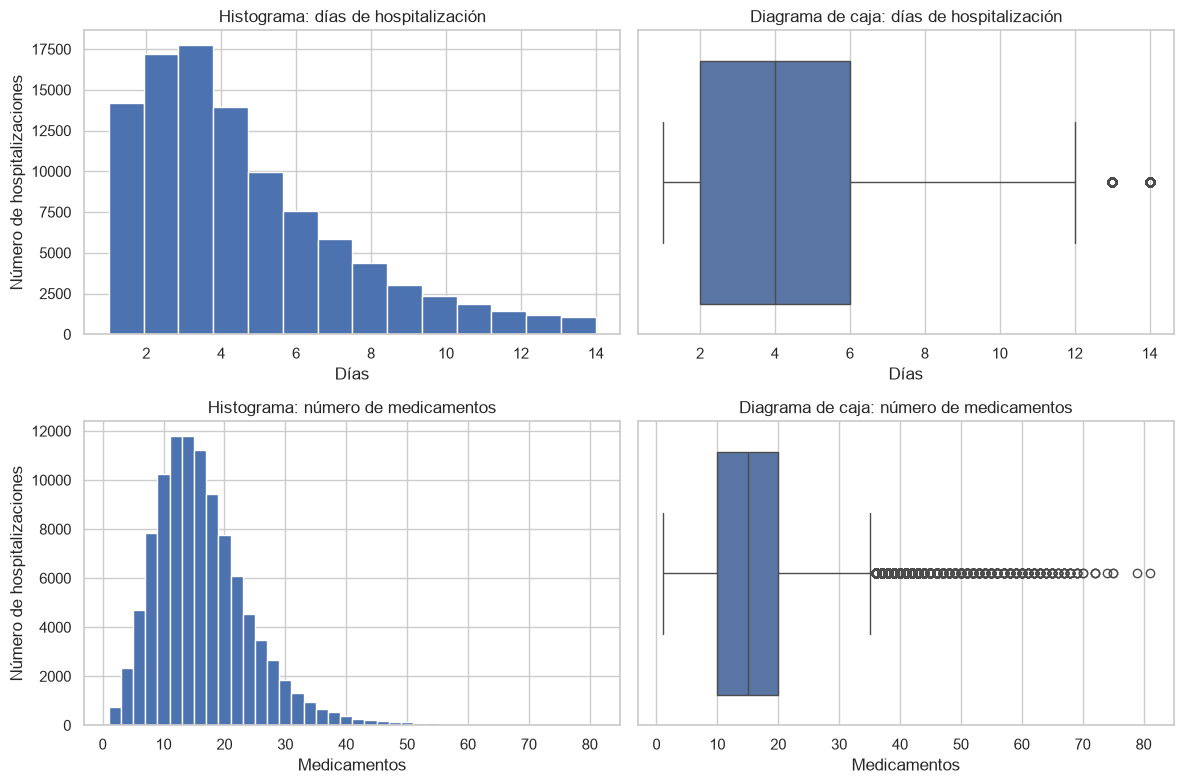

In [46]:
# Histogramas y diagramas de caja de dos variables
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.hist(df_original["time_in_hospital"], bins=14, edgecolor="white")
plt.title("Histograma: días de hospitalización")
plt.xlabel("Días")
plt.ylabel("Número de hospitalizaciones")

plt.subplot(2, 2, 2)
sns.boxplot(x=df_original["time_in_hospital"])
plt.title("Diagrama de caja: días de hospitalización")
plt.xlabel("Días")

plt.subplot(2, 2, 3)
plt.hist(df_original["num_medications"], bins=40, edgecolor="white")
plt.title("Histograma: número de medicamentos")
plt.xlabel("Medicamentos")
plt.ylabel("Número de hospitalizaciones")

plt.subplot(2, 2, 4)
sns.boxplot(x=df_original["num_medications"])
plt.title("Diagrama de caja: número de medicamentos")
plt.xlabel("Medicamentos")

plt.tight_layout()
plt.show()

**Interpretación:**
* **Histograma de días:** la mayoría de hospitalizaciones dura entre 1 y 4 días (la barra más alta está en 3 días). Las barras van bajando hacia la derecha, es decir, la distribución tiene una **cola hacia la derecha**: pocas estancias son largas.
* **Caja de días:** la caja va de 2 a 6 días y la línea del centro (mediana) está en 4. Los puntos de 13 y 14 días salen como atípicos, pero están dentro del rango del estudio (1 a 14 días).
* **Histograma de medicamentos:** la mayoría recibió entre 10 y 20 medicamentos, con forma parecida a una campana pero con la cola larga hacia la derecha.
* **Caja de medicamentos:** hay muchos puntos por encima de 35 medicamentos. Son pacientes con tratamientos más complejos.

### Gráfico de frecuencias de `readmitted`
Usamos los valores y ocurrencias que calculamos con `np.unique` y escribimos el porcentaje sobre cada barra.

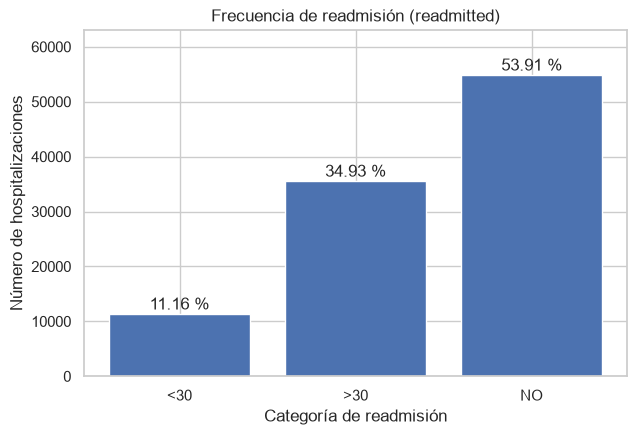

In [47]:
# Gráfico de barras de readmitted
plt.figure(figsize=(7, 4.5))
plt.bar(valores, ocurrencias)
for i in range(len(valores)):
    plt.text(i, ocurrencias[i] + 800, str(porcentajes[i]) + " %", ha="center")
plt.title("Frecuencia de readmisión (readmitted)")
plt.xlabel("Categoría de readmisión")
plt.ylabel("Número de hospitalizaciones")
plt.ylim(0, ocurrencias.max() * 1.15)
plt.show()

**Interpretación:** la barra de `NO` es la más alta, seguida de `>30`. La categoría `<30`, que es la que más le preocupa a un hospital, es la más pequeña (≈ 11 %). Si después se quisiera predecir `<30`, habría que tomar en cuenta este **desbalance**.

### Relación descriptiva con la readmisión
Con `groupby("readmitted")` agrupamos las hospitalizaciones por categoría de readmisión y con `mean()` calculamos el promedio de cada variable en cada grupo. Esto **solo describe** diferencias; no demuestra que una cosa cause la otra.

In [48]:
# Promedio de cada variable según la categoría de readmisión
promedios = df_original.groupby("readmitted")[VARIABLES].mean()
display(promedios.round(3))

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
readmitted,,,,,,,
<30,4.7680,44.2260,1.2810,16.9030,0.4370,0.3570,1.2240
>30,4.4960,43.8370,1.2500,16.2830,0.4960,0.2840,0.8390
NO,4.2540,42.3820,1.4100,15.6700,0.2730,0.1090,0.3820


**Interpretación:** las hospitalizaciones con readmisión `<30` tienen, en promedio, un poco más de días de estancia y de medicamentos, y sobre todo **más hospitalizaciones en el año anterior** (`number_inpatient` es más de tres veces el del grupo `NO`). Esto sugiere que los pacientes que ya venían internándose seguido tienden a volver pronto, pero **no podemos afirmar que sea la causa**: solo es una diferencia de promedios.

### Valores atípicos con el método box plot (IQR)
Usamos el mismo método del Programa3:
* **Q1** (percentil 25) y **Q3** (percentil 75) con `stats.scoreatpercentile`.
* **RIC** = Q3 − Q1 (rango intercuartílico, en inglés IQR).
* **Límite inferior** = Q1 − 1,5 × RIC y **límite superior** = Q3 + 1,5 × RIC.
* Con `np.where` buscamos las posiciones de los valores que quedan fuera de esos límites.

Usamos la función `find_limits_BP` del Programa3. La única diferencia es que ahora también devuelve los límites, para mostrarlos en la tabla.

In [49]:
# Función que, dada una columna, devuelve los límites y la posición de los outliers según el método box plot
def find_limits_BP(variable):

    # Seleccionamos los umbrales a partir de los cuales vamos a considerar outliers
    Q1 = stats.scoreatpercentile(variable, 25)
    Q3 = stats.scoreatpercentile(variable, 75)
    RIC = Q3 - Q1
    li = Q1 - 1.5*RIC #xmin
    ls = Q3 + 1.5*RIC #xmax

    # Buscamos la posición de los outliers
    pos_i = np.where(variable < li)[0]
    pos_s = np.where(variable > ls)[0]
    pos_outliers = np.concatenate((pos_i, pos_s))

    return li, ls, pos_outliers

# Aplicamos la función a cada una de las 7 variables con un ciclo for
resultados = []
for variable in VARIABLES:
    li, ls, pos_outliers = find_limits_BP(df_original[variable])
    cantidad = len(pos_outliers)
    porcentaje = round(cantidad / len(df_original) * 100, 2)
    resultados.append([variable, li, ls, cantidad, porcentaje])

tabla_outliers = pd.DataFrame(resultados, columns=["Variable", "Límite inferior", "Límite superior",
                                                    "Número de outliers", "Porcentaje (%)"])
display(tabla_outliers)

,Variable,Límite inferior,Límite superior,Número de outliers,Porcentaje (%)
0,time_in_hospital,-4.0000,12.0000,2252,2.2100
1,num_lab_procedures,-8.0000,96.0000,143,0.1400
2,num_procedures,-3.0000,5.0000,4954,4.8700
3,num_medications,-5.0000,35.0000,2557,2.5100
4,number_outpatient,0.0000,0.0000,16739,16.4500
5,number_emergency,0.0000,0.0000,11383,11.1900
6,number_inpatient,-1.5000,2.5000,7049,6.9300


**Interpretación y decisión:**
* En `time_in_hospital` hay **2 252 atípicos (≈ 2,2 %)**: son las estancias de 13 y 14 días.
* En `num_medications` hay **2 557 atípicos (≈ 2,5 %)**: pacientes con más de 35 medicamentos.
* En `number_outpatient`, `number_emergency` y `number_inpatient` el porcentaje es alto (hasta ≈ 16 %) porque Q1 y Q3 valen 0. Con el RIC igual a 0, **cualquier visita** ya cuenta como atípica, y eso no tiene sentido clínico.

**Decisión: conservamos todos los valores atípicos**, porque:
1. Todos son valores **posibles en la vida real** (una persona puede tomar 40 medicamentos o haber ido muchas veces a emergencia).
2. No son errores de digitación: no hay negativos ni valores fuera de los rangos del estudio.
3. Los pacientes con valores extremos pueden ser justamente los más importantes para estudiar las readmisiones.
4. Borrarlos solo por pasar un límite estadístico cambiaría la población.

En el Programa3 eliminamos los outliers (`new_df`) porque eran datos de ejemplo. Aquí son pacientes reales, por eso la decisión es distinta. Lo que sí tomamos en cuenta es que estos valores **influyen** en Min-Max y en Z-score (Pasos 6 y 7).

---
## Paso 4. Fase 3 de CRISP-DM: Selección y limpieza

### Reglas de limpieza
Antes de tocar los datos, escribimos las reglas que vamos a seguir:

| Regla | Qué hacemos | Por qué |
|---|---|---|
| **R1** | Cambiamos el texto `?` por vacío (`NaN`) | Para que todos los faltantes estén marcados igual |
| **R2** | En `max_glu_serum` y `A1Cresult` rellenamos los vacíos con `None` | Según la documentación, `None` significa "prueba no realizada", no falta de información |
| **R3** | Eliminamos la columna `weight` | Tiene ≈ 97 % de faltantes y no está entre las variables a escalar |
| **R4** | En `race`, `payer_code`, `medical_specialty`, `diag_1`, `diag_2` y `diag_3` rellenamos los vacíos con "Desconocido" | Así no perdemos filas y queda claro que el dato no se registró. **No inventamos valores** |
| **R5** | Eliminamos filas completamente duplicadas y `encounter_id` repetidos. **No** eliminamos repeticiones de `patient_nbr` | Un paciente puede tener varias hospitalizaciones válidas |
| **R6** | Eliminamos las filas con `gender = Unknown/Invalid` | Es un valor inválido y son muy pocas filas |
| **R7** | Convertimos `admission_type_id`, `discharge_disposition_id` y `admission_source_id` a texto | Para que nadie los use como números por error |
| **R8** | Verificamos que las 7 variables numéricas no tengan vacíos ni negativos y que la estancia esté entre 1 y 14 días | Para asegurar que lo que vamos a escalar está correcto |

Para rellenar (R2 y R4) usamos `SimpleImputer`, como en el Programa4, pero con `strategy='constant'`. En el Programa4 usamos `strategy='mean'` porque los datos eran números; aquí las columnas son **texto**, así que no se puede sacar una media. Con `'constant'` rellenamos con un valor fijo que nosotros elegimos.

Cada regla queda anotada en el **registro de limpieza** con las filas y columnas antes y después.

In [50]:
# Trabajamos sobre una copia; df_original no se modifica
df_limpio = df_original.copy()

# Lista donde anotamos cada decisión
registro_limpieza = []

# Función para anotar una regla con el tamaño antes y después
def registrar(regla, decision, antes, despues, detalle):
    registro_limpieza.append([regla, decision, antes[0], antes[1], despues[0], despues[1], detalle])

# R1: cambiamos "?" por NaN
antes = df_limpio.shape
cantidad = (df_limpio == "?").sum().sum()
df_limpio = df_limpio.replace("?", np.nan)
registrar("R1", "Cambiar '?' por NaN", antes, df_limpio.shape, str(cantidad) + " celdas cambiadas")

# R2: los vacíos de las pruebas de laboratorio pasan a la categoría "None"
antes = df_limpio.shape
pruebas = ["max_glu_serum", "A1Cresult"]
cantidad = df_limpio[pruebas].isnull().sum().sum()
imputer_none = SimpleImputer(missing_values=np.nan, strategy='constant', fill_value='None')
df_limpio[pruebas] = imputer_none.fit_transform(df_limpio[pruebas])
registrar("R2", "Vacíos de pruebas -> 'None' (no realizada)", antes, df_limpio.shape, str(cantidad) + " celdas rellenadas")

# R3: eliminamos la columna weight
antes = df_limpio.shape
porcentaje = round(df_limpio["weight"].isnull().mean() * 100, 1)
df_limpio = df_limpio.drop(columns=["weight"])
registrar("R3", "Eliminar la columna weight", antes, df_limpio.shape, str(porcentaje) + " % faltante")

# R4: los vacíos de texto pasan a "Desconocido"
antes = df_limpio.shape
categoricas = ["race", "payer_code", "medical_specialty", "diag_1", "diag_2", "diag_3"]
cantidad = df_limpio[categoricas].isnull().sum().sum()
imputer_desconocido = SimpleImputer(missing_values=np.nan, strategy='constant', fill_value='Desconocido')
df_limpio[categoricas] = imputer_desconocido.fit_transform(df_limpio[categoricas].astype(object))
registrar("R4", "Vacíos categóricos -> 'Desconocido'", antes, df_limpio.shape, str(cantidad) + " celdas rellenadas")

# R5: eliminamos duplicados reales (se conservan los patient_nbr repetidos)
antes = df_limpio.shape
duplicadas = df_limpio.duplicated().sum()
df_limpio = df_limpio.drop_duplicates()
ids_repetidos = df_limpio["encounter_id"].duplicated().sum()
df_limpio = df_limpio.drop_duplicates(subset="encounter_id")
registrar("R5", "Eliminar filas duplicadas y encounter_id repetidos", antes, df_limpio.shape,
          "Duplicadas: " + str(duplicadas) + "; encounter_id repetidos: " + str(ids_repetidos))

# R6: eliminamos el género inválido
antes = df_limpio.shape
invalidos = (df_limpio["gender"] == "Unknown/Invalid").sum()
df_limpio = df_limpio[df_limpio["gender"] != "Unknown/Invalid"]
registrar("R6", "Eliminar gender = Unknown/Invalid", antes, df_limpio.shape, str(invalidos) + " filas")

# R7: los códigos de categoría pasan a texto
antes = df_limpio.shape
for columna in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    df_limpio[columna] = df_limpio[columna].astype(str)
registrar("R7", "Códigos de admisión y alta a texto", antes, df_limpio.shape, "Solo cambia el tipo, no los valores")

# R8: verificamos las 7 variables numéricas
antes = df_limpio.shape
assert df_limpio[VARIABLES].isnull().sum().sum() == 0, "Hay vacíos en las variables numéricas"
assert (df_limpio[VARIABLES] >= 0).all().all(), "Hay valores negativos"
assert df_limpio["time_in_hospital"].between(1, 14).all(), "Hay estancias fuera de 1 a 14 días"
registrar("R8", "Verificar las 7 variables numéricas", antes, df_limpio.shape, "Sin vacíos, sin negativos, estancia de 1 a 14 días")

# Mostramos el registro de limpieza (criterio C3)
tabla_registro = pd.DataFrame(registro_limpieza, columns=["Regla", "Decisión", "Filas antes", "Columnas antes",
                                                          "Filas después", "Columnas después", "Detalle"])
display(tabla_registro)

,Regla,Decisión,Filas antes,Columnas antes,Filas después,Columnas después,Detalle
0,R1,Cambiar '?' por NaN,101766,50,101766,50,0 celdas cambiadas
1,R2,Vacíos de pruebas -> 'None' (no realizada),101766,50,101766,50,181168 celdas rellenadas
2,R3,Eliminar la columna weight,101766,50,101766,49,96.9 % faltante
3,R4,Vacíos categóricos -> 'Desconocido',101766,49,101766,49,94280 celdas rellenadas
4,R5,Eliminar filas duplicadas y encounter_id repetidos,101766,49,101766,49,Duplicadas: 0; encounter_id repetidos: 0
5,R6,Eliminar gender = Unknown/Invalid,101766,49,101763,49,3 filas
6,R7,Códigos de admisión y alta a texto,101763,49,101763,49,"Solo cambia el tipo, no los valores"
7,R8,Verificar las 7 variables numéricas,101763,49,101763,49,"Sin vacíos, sin negativos, estancia de 1 a 14 días"


### Comprobaciones finales de la limpieza
Revisamos cuántas filas y columnas quedaron, que sigan siendo más de 100 000 filas y que ya no queden vacíos.

In [51]:
print("Filas: %d -> %d" % (df_original.shape[0], df_limpio.shape[0]))
print("Columnas: %d -> %d" % (df_original.shape[1], df_limpio.shape[1]))
print("Filas eliminadas en total:", df_original.shape[0] - df_limpio.shape[0])
print("Vacíos que quedan en el dataset limpio:", df_limpio.isnull().sum().sum())

# Criterio C4
assert df_limpio.shape[0] > 100_000, "Después de limpiar deben quedar más de 100 000 filas"
print("C4 cumplido: siguen quedando más de 100 000 filas.")

# Dato informativo: altas por fallecimiento o cuidados paliativos
fallecidos = df_limpio["discharge_disposition_id"].isin(["11", "19", "20", "21"]).sum()
print("\nHospitalizaciones con alta por fallecimiento o paliativos (códigos 11, 19, 20, 21):", fallecidos)

Filas: 101766 -> 101763
Columnas: 50 -> 49
Filas eliminadas en total: 3
Vacíos que quedan en el dataset limpio: 0
C4 cumplido: siguen quedando más de 100 000 filas.

Hospitalizaciones con alta por fallecimiento o paliativos (códigos 11, 19, 20, 21): 1652


**Interpretación:**
* Solo eliminamos **3 filas** (género inválido) y **1 columna** (`weight`). El dataset limpio tiene **101 763 filas**, así que se cumple la condición de más de 100 000 registros **sin duplicar ni inventar datos**.
* No había duplicados reales, así que la regla R5 no eliminó nada, pero la dejamos escrita para mostrar que sí lo revisamos.
* Hay **1 652 hospitalizaciones** en las que el paciente falleció o pasó a cuidados paliativos. Esos pacientes **no pueden ser readmitidos**. Como esta práctica es solo descriptiva, **no las eliminamos**, pero si después se hiciera un modelo de readmisión habría que analizarlas aparte.

### Copia de las variables numéricas limpias
Antes de transformar, guardamos en `X` una copia con las 7 variables limpias, como hicimos en el ejercicio de Iris.

Usamos `encounter_id` como **índice** con `set_index`. Así cada fila conserva su identificador y siempre sabemos a qué hospitalización corresponde. `encounter_id` **no se escala**; solo sirve como referencia.

In [52]:
# Copia de las 7 variables limpias, con encounter_id como referencia
X = df_limpio.set_index("encounter_id")[VARIABLES].copy()
X.to_csv("variables_numericas_limpias.csv")

print("Tamaño de X:", X.shape)
X.head()

Tamaño de X: (101763, 7)


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
encounter_id,,,,,,,
2278392,1,41,0,1,0,0,0
149190,3,59,0,18,0,0,0
64410,2,11,5,13,2,0,1
500364,2,44,1,16,0,0,0
16680,1,51,0,8,0,0,0


---
## Paso 5. Selección de variables cuantitativas

Usamos las 7 variables que pide la guía:

| Variable | Significado |
|---|---|
| `time_in_hospital` | Duración de la hospitalización en días |
| `num_lab_procedures` | Número de procedimientos de laboratorio |
| `num_procedures` | Número de procedimientos distintos de laboratorio |
| `num_medications` | Número de medicamentos distintos administrados |
| `number_outpatient` | Visitas ambulatorias durante el año anterior |
| `number_emergency` | Visitas de emergencia durante el año anterior |
| `number_inpatient` | Hospitalizaciones durante el año anterior |

Antes de transformarlas, revisamos lo que dice UCI sobre ellas y comprobamos en nuestros datos que sean numéricas y que **ninguna sea constante** (todos los valores iguales).

In [53]:
# Lo que dice UCI sobre estas variables
display(dataset.variables[dataset.variables["name"].isin(VARIABLES)])

# Lo que vemos en nuestros datos limpios
print(X.dtypes)
print()
print("Valores distintos por variable:")
print(X.nunique())

,name,role,type,demographic,description,units,missing_values
9,time_in_hospital,Feature,Integer,None,Integer number of days between admission and discharge,None,no
12,num_lab_procedures,Feature,Integer,None,Number of lab tests performed during the encounter,None,no
13,num_procedures,Feature,Integer,None,Number of procedures (other than lab tests) performed during the encounter,None,no
14,num_medications,Feature,Integer,None,Number of distinct generic names administered during the encounter,None,no
15,number_outpatient,Feature,Integer,None,Number of outpatient visits of the patient in the year preceding the encounter,None,no
16,number_emergency,Feature,Integer,None,Number of emergency visits of the patient in the year preceding the encounter,None,no
17,number_inpatient,Feature,Integer,None,Number of inpatient visits of the patient in the year preceding the encounter,None,no


time_in_hospital      int64
num_lab_procedures    int64
num_procedures        int64
num_medications       int64
number_outpatient     int64
number_emergency      int64
number_inpatient      int64
dtype: object

Valores distintos por variable:
time_in_hospital       14
num_lab_procedures    118
num_procedures          7
num_medications        75
number_outpatient      39
number_emergency       33
number_inpatient       21
dtype: int64


### Variables que dejamos fuera del escalamiento
* `encounter_id` y `patient_nbr`: son identificadores.
* `admission_type_id`, `discharge_disposition_id` y `admission_source_id`: son códigos de categorías.
* `age`: está en intervalos, no es una edad exacta.
* `readmitted`: es la variable de referencia y es categórica.

**Interpretación:** las 7 variables son enteras (`int64`), no tienen vacíos y todas tienen muchos valores distintos, así que **ninguna es constante** y se pueden escalar sin problema.

---
## Paso 6. Normalización Min-Max

La normalización lleva cada variable al rango **[0, 1]** con esta fórmula:

$$x_{normalizado} = \frac{x - x_{mínimo}}{x_{máximo} - x_{mínimo}}$$

* El valor más pequeño de la variable se convierte en **0**.
* El valor más grande se convierte en **1**.
* Todo lo demás queda en medio, en la misma proporción.

Igual que en el Programa1 y en el ejercicio de Iris:
* Creamos el normalizador con `preprocessing.MinMaxScaler()`.
* `fit_transform()` **aprende** el mínimo y el máximo de cada columna y **transforma** los datos.
* El resultado sale como arreglo sin nombres, así que lo volvemos a convertir en tabla con `pd.DataFrame`, con las mismas columnas y el mismo índice (`encounter_id`).

In [54]:
# Normalizamos una copia de las variables limpias
normalizer = preprocessing.MinMaxScaler(feature_range=(0, 1))
X_norm = normalizer.fit_transform(X.copy())
X_norm = pd.DataFrame(X_norm, columns=X.columns, index=X.index)

# Primeras 10 filas normalizadas
X_norm.head(10)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
encounter_id,,,,,,,
2278392,0.0000,0.3053,0.0000,0.0000,0.0000,0.0000,0.0000
149190,0.1538,0.4427,0.0000,0.2125,0.0000,0.0000,0.0000
64410,0.0769,0.0763,0.8333,0.1500,0.0476,0.0000,0.0476
500364,0.0769,0.3282,0.1667,0.1875,0.0000,0.0000,0.0000
16680,0.0000,0.3817,0.0000,0.0875,0.0000,0.0000,0.0000
35754,0.1538,0.2290,1.0000,0.1875,0.0000,0.0000,0.0000
55842,0.2308,0.5267,0.1667,0.2500,0.0000,0.0000,0.0000
63768,0.3077,0.5496,0.0000,0.1375,0.0000,0.0000,0.0000
12522,0.9231,0.5115,0.3333,0.3375,0.0000,0.0000,0.0000


### Mínimo y máximo antes y después
Comparamos el mínimo y el máximo de cada variable antes y después de normalizar. Para comprobar que quedaron en 0 y 1 usamos una **tolerancia**: aceptamos una diferencia muy pequeña (0,000000001) porque la computadora puede tener errores mínimos al trabajar con decimales.

In [55]:
# Tabla de mínimo y máximo antes y después
tabla_minmax = pd.DataFrame({
    "Mínimo antes": X.min(),
    "Máximo antes": X.max(),
    "Mínimo después": X_norm.min(),
    "Máximo después": X_norm.max()
})
display(tabla_minmax)

# Comprobación con tolerancia (criterio C5)
tolerancia = 1e-9
minimo_correcto = (abs(X_norm.min() - 0) < tolerancia).all()
maximo_correcto = (abs(X_norm.max() - 1) < tolerancia).all()
print("¿Todos los mínimos son 0?", minimo_correcto)
print("¿Todos los máximos son 1?", maximo_correcto)
print("¿Se mantienen las mismas filas?", X_norm.shape == X.shape)

,Mínimo antes,Máximo antes,Mínimo después,Máximo después
time_in_hospital,1,14,0.0000,1.0000
num_lab_procedures,1,132,0.0000,1.0000
num_procedures,0,6,0.0000,1.0000
num_medications,1,81,0.0000,1.0000
number_outpatient,0,42,0.0000,1.0000
number_emergency,0,76,0.0000,1.0000
number_inpatient,0,21,0.0000,1.0000


¿Todos los mínimos son 0? True
¿Todos los máximos son 1? True
¿Se mantienen las mismas filas? True


**Interpretación:** las 7 variables quedaron con mínimo **0** y máximo **1**, y la tabla normalizada tiene las mismas 101 763 filas que la original. Se cumple el criterio **C5**.

### ¿Cómo influyen los valores extremos?
Min-Max depende **solo del mínimo y del máximo**. Si hay un valor muy grande, ese valor "estira" la escala y todos los demás quedan apretados cerca de 0. Lo vemos con `number_emergency`, cuyo máximo es 76.

In [58]:
# Efecto del valor extremo en number_emergency
maximo = X["number_emergency"].max()
print("Máximo de number_emergency:", maximo)
print("Una persona con 1 visita queda en:", round(1 / maximo, 4))
print("Una persona con 5 visitas queda en:", round(5 / maximo, 4))
print("Media normalizada de number_emergency:", round(X_norm["number_emergency"].mean(), 4))

Máximo de number_emergency: 76
Una persona con 1 visita queda en: 0.0132
Una persona con 5 visitas queda en: 0.0658
Media normalizada de number_emergency: 0.0026


**Interpretación:** por un solo paciente con 76 visitas, alguien con 5 visitas (que ya es bastante) queda en apenas **0,066**. Casi todos los valores quedan amontonados cerca de 0. Esa es la principal **debilidad de Min-Max: es muy sensible a los valores extremos**.

### ¿Qué pasa con una columna constante?
Si todos los valores de una columna son iguales, el máximo y el mínimo son el mismo número y el denominador de la fórmula sería **cero**. `MinMaxScaler` evita el error y devuelve **0** en toda la columna. Lo probamos con un ejemplo pequeño, como los del Programa1.

In [59]:
# Ejemplo: la primera columna es constante (todos valen 5)
X_constante = np.array([[5., 1.],
                        [5., 2.],
                        [5., 3.]])
print(preprocessing.MinMaxScaler().fit_transform(X_constante))

[[0.  0. ]
 [0.  0.5]
 [0.  1. ]]


**Interpretación:** la columna constante queda toda en **0** porque no tiene variación que mostrar, y la otra columna queda en 0; 0,5 y 1. En nuestras 7 variables esto no pasa, porque ya comprobamos que ninguna es constante.

---
## Paso 7. Estandarización Z-score

La estandarización transforma cada variable para que tenga **media 0** y **desviación estándar 1**:

$$z = \frac{x - \mu}{\sigma}$$

donde **μ** es la media y **σ** es la desviación estándar de la variable.

El valor z dice **a cuántas desviaciones estándar está un dato de la media**. Por ejemplo, z = 2 significa "dos desviaciones por encima del promedio".

Igual que en el Programa2, creamos el estandarizador con `preprocessing.StandardScaler()`. Lo aplicamos sobre **otra copia de `X`** (los datos limpios originales), **no** sobre `X_norm`.

In [60]:
# Estandarizamos otra copia de las variables limpias (NO X_norm)
standardizer = preprocessing.StandardScaler()
X_std = standardizer.fit_transform(X.copy())
X_std = pd.DataFrame(X_std, columns=X.columns, index=X.index)

# Primeras 10 filas estandarizadas
X_std.head(10)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
encounter_id,,,,,,,
2278392,-1.1377,-0.1065,-0.7854,-1.8483,-0.2915,-0.2126,-0.5033
149190,-0.4677,0.8084,-0.7854,0.2434,-0.2915,-0.2126,-0.5033
64410,-0.8027,-1.6314,2.1458,-0.3718,1.2867,-0.2126,0.2886
500364,-0.8027,0.0460,-0.1991,-0.0027,-0.2915,-0.2126,-0.5033
16680,-1.1377,0.4018,-0.7854,-0.9870,-0.2915,-0.2126,-0.5033
35754,-0.4677,-0.6148,2.7321,-0.0027,-0.2915,-0.2126,-0.5033
55842,-0.1327,1.3675,-0.1991,0.6125,-0.2915,-0.2126,-0.5033
63768,0.2023,1.5200,-0.7854,-0.4948,-0.2915,-0.2126,-0.5033
12522,2.8823,1.2658,0.3871,1.4738,-0.2915,-0.2126,-0.5033


### Media y desviación después de estandarizar
Comprobamos que la media quede en 0 y la desviación en 1, otra vez con una tolerancia.

Usamos `std(ddof=0)`. pandas, por defecto, calcula la desviación dividiendo para **n − 1** (`ddof=1`), pero `StandardScaler` divide para **n** (`ddof=0`). Para que la comprobación sea justa, usamos lo mismo que usa el estandarizador.

In [61]:
# Tabla de media y desviación antes y después
tabla_z = pd.DataFrame({
    "Media antes": X.mean(),
    "Desviación antes": X.std(ddof=0),
    "Media después": X_std.mean(),
    "Desviación después": X_std.std(ddof=0),
    "Mínimo z": X_std.min(),
    "Máximo z": X_std.max()
})
display(tabla_z.round(4))

# Comprobación con tolerancia (criterio C6)
tolerancia = 1e-6
media_correcta = (abs(X_std.mean() - 0) < tolerancia).all()
desviacion_correcta = (abs(X_std.std(ddof=0) - 1) < tolerancia).all()
print("¿Todas las medias son 0?", media_correcta)
print("¿Todas las desviaciones son 1?", desviacion_correcta)

,Media antes,Desviación antes,Media después,Desviación después,Mínimo z,Máximo z
time_in_hospital,4.3960,2.9851,0.0000,1.0000,-1.1377,3.2173
num_lab_procedures,43.0959,19.6741,-0.0000,1.0000,-2.1397,4.5188
num_procedures,1.3397,1.7058,-0.0000,1.0000,-0.7854,2.7321
num_medications,16.0218,8.1275,-0.0000,1.0000,-1.8483,7.9948
number_outpatient,0.3694,1.2673,0.0000,1.0000,-0.2915,32.8505
number_emergency,0.1978,0.9305,0.0000,1.0000,-0.2126,81.4656
number_inpatient,0.6356,1.2629,0.0000,1.0000,-0.5033,16.1255


¿Todas las medias son 0? True
¿Todas las desviaciones son 1? True


**Interpretación:** las 7 variables quedaron con media **0** y desviación **1**. Se cumple el criterio **C6**.

### ¿Por qué aparecen valores negativos y fuera de [0, 1]?
* **Negativos:** todo valor que esté **por debajo de la media** da un z negativo. Por ejemplo, 1 día de hospitalización está por debajo del promedio (≈ 4,4 días), así que su z es **−1,14**.
* **Mayores que 1:** Z-score **no tiene un límite fijo**. En `number_emergency` el máximo llega a un z de aproximadamente **81**, porque 76 visitas está a más de 80 desviaciones del promedio. Esto muestra que Z-score tampoco elimina el efecto de los extremos; solo lo expresa en desviaciones.

### ¿Qué pasa con una columna constante?
Su desviación estándar es 0. `StandardScaler` no divide para cero: deja toda la columna en **0**, y la desviación del resultado también es 0. Lo probamos con el mismo ejemplo de antes.

In [62]:
# Mismo ejemplo con una columna constante
X_constante_std = preprocessing.StandardScaler().fit_transform(X_constante)
print(X_constante_std)
print("Desviación de la columna constante:", X_constante_std[:, 0].std())

[[ 0.         -1.22474487]
 [ 0.          0.        ]
 [ 0.          1.22474487]]
Desviación de la columna constante: 0.0


### Nota importante: fuga de datos
En esta práctica ajustamos los escaladores con **todos** los datos porque solo estamos describiendo. Pero si después se construye un modelo, hay que hacerlo como en los Programas 7, 9 y 10:
1. Separar primero los datos en **entrenamiento** y **test** con `train_test_split` (hold out).
2. Aplicar `fit_transform()` **solo al entrenamiento**.
3. Aplicar solo `transform()` al test, con la media y la desviación aprendidas del entrenamiento.
4. Si se usa validación cruzada, meter el escalador dentro de un **Pipeline**, como en el Programa10, para que se ajuste dentro de cada bolsa.
5. Separar **por paciente** (`patient_nbr`), para que un mismo paciente no quede al mismo tiempo en entrenamiento y en test.

Si no se hace así, el modelo "conoce" información del test y sus resultados se ven mejores de lo que realmente son.

---
## Paso 8. Comparación y exportación

### Tabla de comparación estadística
Comparamos las tres versiones (original limpia, normalizada y estandarizada) con mínimo, máximo, media y desviación estándar. Creamos una función `resumen` que calcula estas cuatro medidas para una versión, y luego unimos las tres tablas con `pd.concat`.

In [63]:
# Función que calcula las 4 medidas de una versión de los datos
def resumen(datos, nombre):
    tabla = pd.DataFrame({
        nombre + " | mínimo": datos.min(),
        nombre + " | máximo": datos.max(),
        nombre + " | media": datos.mean(),
        nombre + " | desviación": datos.std(ddof=0)
    })
    return tabla

# Unimos las tres versiones en una sola tabla
tabla_comparacion = pd.concat([resumen(X, "Original"),
                               resumen(X_norm, "Min-Max"),
                               resumen(X_std, "Z-score")], axis=1)
display(tabla_comparacion.round(4))

# Guardamos la tabla
tabla_comparacion.to_csv("tabla_comparacion_estadistica.csv")

,Original | mínimo,Original | máximo,Original | media,Original | desviación,Min-Max | mínimo,Min-Max | máximo,Min-Max | media,Min-Max | desviación,Z-score | mínimo,Z-score | máximo,Z-score | media,Z-score | desviación
time_in_hospital,1,14,4.3960,2.9851,0.0000,1.0000,0.2612,0.2296,-1.1377,3.2173,0.0000,1.0000
num_lab_procedures,1,132,43.0959,19.6741,0.0000,1.0000,0.3213,0.1502,-2.1397,4.5188,-0.0000,1.0000
num_procedures,0,6,1.3397,1.7058,0.0000,1.0000,0.2233,0.2843,-0.7854,2.7321,-0.0000,1.0000
num_medications,1,81,16.0218,8.1275,0.0000,1.0000,0.1878,0.1016,-1.8483,7.9948,-0.0000,1.0000
number_outpatient,0,42,0.3694,1.2673,0.0000,1.0000,0.0088,0.0302,-0.2915,32.8505,0.0000,1.0000
number_emergency,0,76,0.1978,0.9305,0.0000,1.0000,0.0026,0.0122,-0.2126,81.4656,0.0000,1.0000
number_inpatient,0,21,0.6356,1.2629,0.0000,1.0000,0.0303,0.0601,-0.5033,16.1255,0.0000,1.0000


**Interpretación:**
* En los **datos originales** cada variable tiene su propia escala: `num_lab_procedures` llega a 132 y `num_procedures` solo a 6. Si se usan así, la variable con números más grandes "pesa" más en un modelo.
* Con **Min-Max** todas quedan entre 0 y 1, pero sus medias son muy distintas (por ejemplo, `number_emergency` queda con media casi 0 por el extremo de 76).
* Con **Z-score** todas tienen media 0 y desviación 1, pero sus mínimos y máximos son diferentes y pueden ser negativos o mucho mayores que 1.

### Comparación visual de las 7 variables
Igual que en el ejercicio de Iris, dibujamos un diagrama de caja de las 7 variables en cada versión.

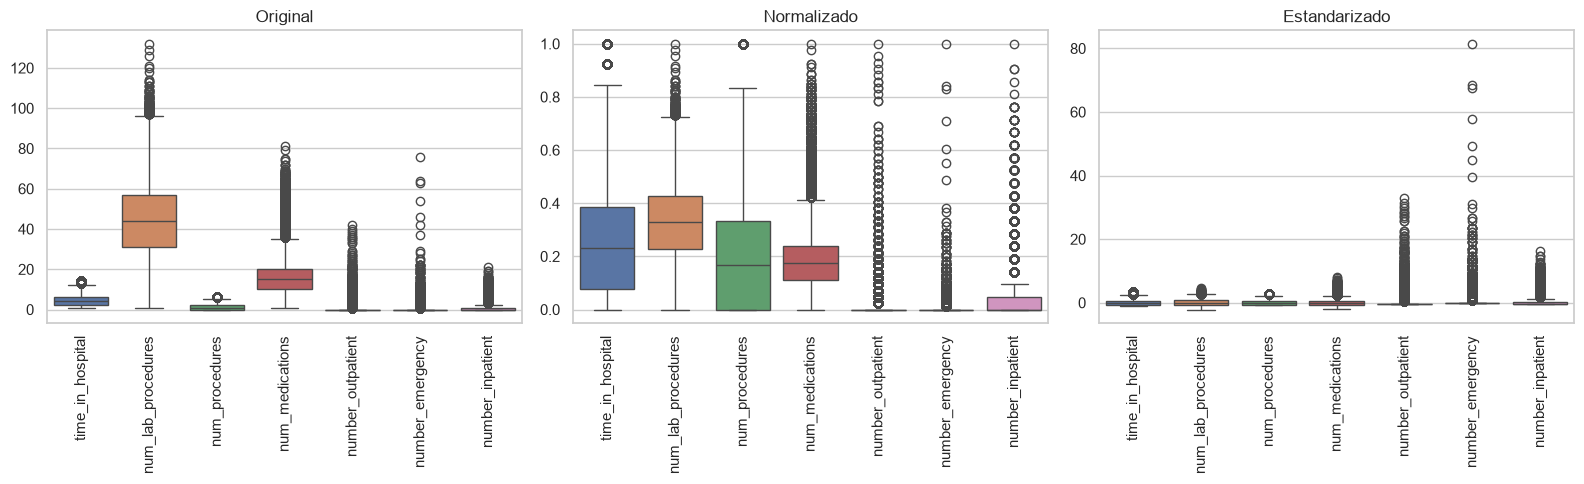

In [65]:
# Comparación visual
plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1)
sns.boxplot(data=X)
plt.title("Original")
plt.xticks(rotation=90)
plt.subplot(1, 3, 2)
sns.boxplot(data=X_norm)
plt.title("Normalizado")
plt.xticks(rotation=90)
plt.subplot(1, 3, 3)
sns.boxplot(data=X_std)
plt.title("Estandarizado")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Interpretación:**
* En **Original** las cajas están a escalas muy distintas: `num_lab_procedures` domina el gráfico y las demás casi no se ven.
* En **Normalizado** todas quedan entre 0 y 1.
* En **Estandarizado** todas se centran alrededor de 0, pero las variables de visitas del año anterior tienen puntos muy altos (hasta ≈ 81).

### Histogramas de dos variables en sus tres versiones
Comparamos `time_in_hospital` y `num_medications`. Usamos el mismo número de barras en las tres versiones de cada variable para que los gráficos se puedan comparar.

Además calculamos la **asimetría** (`skew()`), que mide qué tan cargada está la distribución hacia un lado. Si la forma no cambia, la asimetría debe ser igual en las tres versiones.

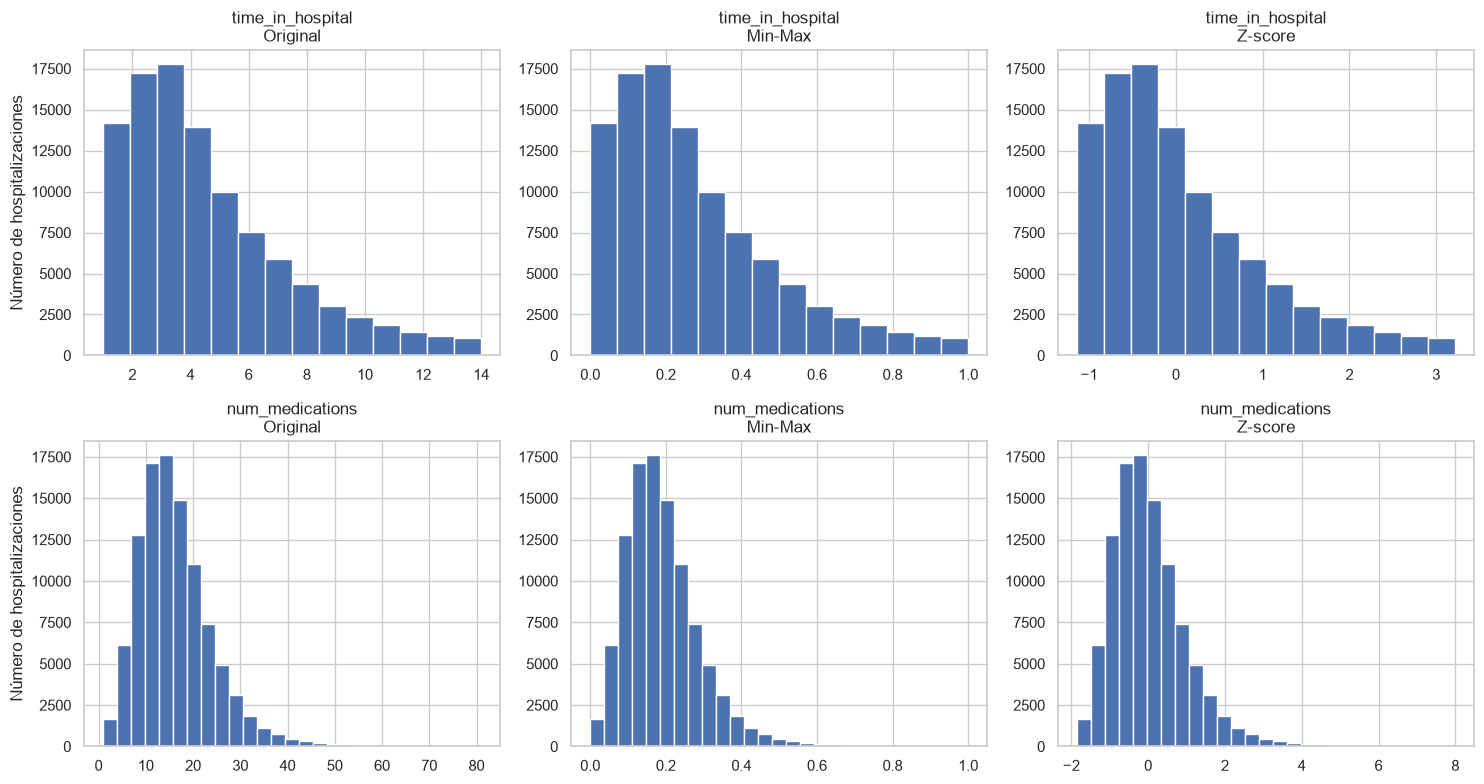

,Original,Min-Max,Z-score
time_in_hospital,1.1340,1.1340,1.1340
num_medications,1.3267,1.3267,1.3267


In [66]:
# Histogramas de las tres versiones
variables_grafico = ["time_in_hospital", "num_medications"]
barras = {"time_in_hospital": 14, "num_medications": 27}

plt.figure(figsize=(15, 8))
posicion = 1
for variable in variables_grafico:
    plt.subplot(2, 3, posicion)
    plt.hist(X[variable], bins=barras[variable], edgecolor="white")
    plt.title(variable + "\nOriginal")
    plt.ylabel("Número de hospitalizaciones")

    plt.subplot(2, 3, posicion + 1)
    plt.hist(X_norm[variable], bins=barras[variable], edgecolor="white")
    plt.title(variable + "\nMin-Max")

    plt.subplot(2, 3, posicion + 2)
    plt.hist(X_std[variable], bins=barras[variable], edgecolor="white")
    plt.title(variable + "\nZ-score")

    posicion = posicion + 3
plt.tight_layout()
plt.show()

# Asimetría de cada versión
asimetria = pd.DataFrame({"Original": X[variables_grafico].skew(),
                          "Min-Max": X_norm[variables_grafico].skew(),
                          "Z-score": X_std[variables_grafico].skew()})
display(asimetria.round(4))

**Interpretación:**
* Los tres histogramas de cada fila tienen **la misma forma**. Lo único que cambia son los números del eje horizontal: de días o medicamentos pasan a valores entre 0 y 1 (Min-Max) o a valores alrededor de 0 (Z-score).
* La tabla de asimetría lo confirma: el valor es **el mismo** en las tres versiones. Esto pasa porque Min-Max y Z-score son **transformaciones lineales**: solo restan un número y dividen para otro. Mueven y estiran la escala, pero **no corrigen la asimetría** ni cambian el orden de los datos.
* Si quisiéramos volver la distribución más simétrica, habría que usar otra técnica, como un logaritmo, y eso ya no es solo cambiar la escala.

### Demostración manual con cinco valores
Escogemos cinco hospitalizaciones con distintos valores de `time_in_hospital` (1, 4, 7, 10 y 14 días) y hacemos los cálculos a mano con las fórmulas. Luego los comparamos con lo que dio Python, como en el Programa4, donde también comprobamos a mano el cálculo de la media.

Los parámetros que necesitamos son el mínimo, el máximo, la media y la desviación (`ddof=0`) de la variable.

In [67]:
# Parámetros de time_in_hospital
variable = "time_in_hospital"
x_min = X[variable].min()
x_max = X[variable].max()
media = X[variable].mean()
desviacion = X[variable].std(ddof=0)

print("Parámetros de", variable)
print("  mínimo =", x_min)
print("  máximo =", x_max)
print("  media (μ) =", round(media, 4))
print("  desviación (σ) =", round(desviacion, 4))
print()

# Tomamos la primera hospitalización que tenga cada uno de estos valores
for valor in [1, 4, 7, 10, 14]:
    encounter = X[X[variable] == valor].index[0]
    x = X.loc[encounter, variable]

    # Cálculo manual
    minmax_manual = (x - x_min) / (x_max - x_min)
    z_manual = (x - media) / desviacion

    # Resultado de Python
    minmax_python = X_norm.loc[encounter, variable]
    z_python = X_std.loc[encounter, variable]

    print("encounter_id", encounter, "| x =", x)
    print("  Min-Max: (%d - %d) / (%d - %d) = %.4f   Python: %.4f" % (x, x_min, x_max, x_min, minmax_manual, minmax_python))
    print("  Z-score: (%d - %.4f) / %.4f = %.4f   Python: %.4f" % (x, media, desviacion, z_manual, z_python))
    print("  ¿Coinciden?", abs(minmax_manual - minmax_python) < 1e-9 and abs(z_manual - z_python) < 1e-9)

Parámetros de time_in_hospital
  mínimo = 1
  máximo = 14
  media (μ) = 4.396
  desviación (σ) = 2.9851

encounter_id 2278392 | x = 1
  Min-Max: (1 - 1) / (14 - 1) = 0.0000   Python: 0.0000
  Z-score: (1 - 4.3960) / 2.9851 = -1.1377   Python: -1.1377
  ¿Coinciden? True
encounter_id 55842 | x = 4
  Min-Max: (4 - 1) / (14 - 1) = 0.2308   Python: 0.2308
  Z-score: (4 - 4.3960) / 2.9851 = -0.1327   Python: -0.1327
  ¿Coinciden? True
encounter_id 36900 | x = 7
  Min-Max: (7 - 1) / (14 - 1) = 0.4615   Python: 0.4615
  Z-score: (7 - 4.3960) / 2.9851 = 0.8723   Python: 0.8723
  ¿Coinciden? True
encounter_id 42570 | x = 10
  Min-Max: (10 - 1) / (14 - 1) = 0.6923   Python: 0.6923
  Z-score: (10 - 4.3960) / 2.9851 = 1.8773   Python: 1.8773
  ¿Coinciden? True
encounter_id 927786 | x = 14
  Min-Max: (14 - 1) / (14 - 1) = 1.0000   Python: 1.0000
  Z-score: (14 - 4.3960) / 2.9851 = 3.2173   Python: 3.2173
  ¿Coinciden? True


**Interpretación:**
* Con **Min-Max**, 1 día da **0** (es el mínimo), 14 días da **1** (es el máximo) y 7 días da (7 − 1) / 13 ≈ **0,46**.
* Con **Z-score**, 1 día da **−1,14** porque está por debajo de la media (≈ 4,4 días); 4 días queda muy cerca de 0 (**−0,13**); y 14 días da **3,22**, porque está a más de tres desviaciones del promedio.
* En todos los casos el cálculo hecho a mano **coincide** con el de scikit-learn, así que entendemos lo que hace cada escalador por dentro.

### Exportación de los resultados
Exportamos las 7 variables en dos archivos:
* `datos_normalizados.csv`
* `datos_estandarizados.csv`

En los dos usamos `encounter_id` como índice, en el **mismo orden**. Así cada fila se puede unir con el registro original usando `encounter_id`. Después volvemos a leer los archivos para comprobar que quedaron bien.

In [68]:
# Exportamos los dos archivos
X_norm.to_csv("datos_normalizados.csv")
X_std.to_csv("datos_estandarizados.csv")

# Leemos otra vez los archivos para comprobarlos (criterio C7)
norm_leido = pd.read_csv("datos_normalizados.csv", index_col="encounter_id")
std_leido = pd.read_csv("datos_estandarizados.csv", index_col="encounter_id")

print("datos_normalizados.csv:", norm_leido.shape)
print("datos_estandarizados.csv:", std_leido.shape)
print("¿Mismo orden de filas?", (norm_leido.index == std_leido.index).all())
print("¿Mismas columnas?", list(norm_leido.columns) == list(std_leido.columns))
print("¿Todas las filas existen en el original?", norm_leido.index.isin(df_original["encounter_id"]).all())

datos_normalizados.csv: (101763, 7)
datos_estandarizados.csv: (101763, 7)
¿Mismo orden de filas? True
¿Mismas columnas? True
¿Todas las filas existen en el original? True


### Correspondencia con los registros originales
Para mostrar cómo se relacionan los archivos con los datos originales, tomamos las 3 primeras filas y juntamos el valor original de `time_in_hospital` con sus versiones normalizada y estandarizada.

In [69]:
# Ejemplo de unión usando encounter_id
ejemplo = df_original.set_index("encounter_id").loc[norm_leido.index[:3], ["patient_nbr", "time_in_hospital", "readmitted"]]
ejemplo["time_in_hospital normalizado"] = norm_leido["time_in_hospital"].iloc[:3]
ejemplo["time_in_hospital estandarizado"] = std_leido["time_in_hospital"].iloc[:3]
ejemplo

,patient_nbr,time_in_hospital,readmitted,time_in_hospital normalizado,time_in_hospital estandarizado
encounter_id,,,,,
2278392,8222157,1,NO,0.0000,-1.1377
149190,55629189,3,>30,0.1538,-0.4677
64410,86047875,2,NO,0.0769,-0.8027


**Interpretación:** los dos archivos tienen **101 763 filas y 7 columnas**, en el mismo orden y con el mismo `encounter_id`. Se cumple el criterio **C7**. Las filas siguen el mismo orden del archivo original, sin las 3 filas de género inválido que eliminamos en la regla R6. Con `encounter_id` podemos unir cualquier fila con sus datos originales, como muestra la tabla.

### Archivos generados
| Archivo | Contenido |
|---|---|
| `hospitalizaciones_diabetes_original.csv` | Copia original sin cambios (101 766 × 50) |
| `variables_numericas_limpias.csv` | Las 7 variables limpias antes de transformar |
| `datos_normalizados.csv` | Las 7 variables con Min-Max |
| `datos_estandarizados.csv` | Las 7 variables con Z-score |
| `tabla_comparacion_estadistica.csv` | Tabla de comparación de las tres versiones |

---
## Conclusiones

### Respuesta a las preguntas de análisis
* **P1. ¿Cómo se reparten las readmisiones?** Más de la mitad de las hospitalizaciones (≈ 54 %) no tuvo readmisión, cerca del 35 % volvió después de 30 días y alrededor del 11 % volvió antes de 30 días. El grupo que más preocupa (`<30`) es el más pequeño, así que los datos están desbalanceados.
* **P2. ¿Qué tan buenos son los datos?** No hay duplicados reales. Los faltantes se concentran en `weight`, `medical_specialty` y `payer_code`; las 7 variables numéricas están completas. Hay valores atípicos, sobre todo en las visitas del año anterior, pero son valores posibles y los conservamos.
* **P3. ¿Hay diferencias según la readmisión?** De forma descriptiva, las hospitalizaciones con readmisión `<30` tienen en promedio más hospitalizaciones en el año anterior y un poco más de días y medicamentos. Esto no prueba una causa; solo muestra una diferencia que se podría estudiar después.

### ¿Cuándo elegir cada transformación?
* **Min-Max** conviene cuando necesitamos valores en un rango fijo (0 a 1), por ejemplo para algoritmos que usan distancias como KNN o para redes neuronales, y cuando los datos **no tienen extremos muy fuertes**. Si los hay, la mayoría de valores queda apretada cerca de 0.
* **Z-score** conviene cuando queremos saber qué tan lejos está cada dato del promedio, o para modelos que funcionan mejor con datos centrados en 0, como el SVC y el SVR que usamos en los Programas 7, 9 y 10. Tampoco elimina los extremos, pero no los encierra en un rango.
* Ninguna de las dos **corrige la asimetría**: solo cambian la escala.

### Limitaciones
* Los datos son de 1999–2008 y de hospitales de Estados Unidos; no representan la situación actual ni la de Ecuador.
* Cada fila es una hospitalización; el mismo paciente puede aparecer varias veces.
* Ajustamos los escaladores con todos los datos porque el análisis es descriptivo. Para un modelo habría que ajustar solo con el entrenamiento.
* No tratamos la asimetría ni los valores extremos; si se hace un modelo, habría que evaluar otras técnicas.
* Es un trabajo académico y no permite dar diagnósticos ni sacar conclusiones de causa y efecto.

### Cumplimiento de los criterios de éxito
Los criterios C1 a C7 quedaron comprobados en las celdas de los Pasos 3 al 8.

---
## Preguntas de reflexión

**1. ¿Por qué un código categórico numérico no debe escalarse como una medición?**

Porque el número solo es una etiqueta. En `admission_type_id`, el 1 es "emergencia" y el 3 es "electiva", pero el 3 no es "tres veces" el 1 ni hay una distancia real entre ellos. Si lo escalamos, el algoritmo creería que hay un orden y una distancia que no existen.

**2. ¿Cómo afectaría un valor extremo a Min-Max y a Z-score?**

En **Min-Max**, el extremo se vuelve el máximo y todos los demás valores quedan apretados cerca de 0. Lo vimos en `number_emergency`: por un paciente con 76 visitas, alguien con 5 visitas quedó en 0,066. En **Z-score**, el extremo sube la media y la desviación, y él mismo queda con un z muy grande (≈ 81). Los dos métodos se ven afectados.

**3. ¿Por qué una readmisión del mismo paciente no es necesariamente un duplicado?**

Porque cada fila es una hospitalización distinta, con su propio `encounter_id`, sus días de estancia y sus medicamentos. Que `patient_nbr` se repita solo significa que la persona se internó varias veces. Un duplicado sería una fila exactamente igual o un `encounter_id` repetido, y eso no apareció.

**4. ¿Qué diferencia hay entre cambiar de escala y corregir una distribución asimétrica?**

Cambiar de escala (Min-Max o Z-score) solo mueve y estira los valores; la forma del histograma queda igual, como comprobamos con la asimetría, que no cambió. Corregir la asimetría significa cambiar la forma de la distribución, por ejemplo con un logaritmo o una raíz cuadrada, para que la cola larga se acorte.

**5. ¿Cómo evitaría la fuga de información si posteriormente entrenara un modelo?**

Separaría primero los datos en entrenamiento y test, **agrupando por paciente** para que nadie quede en los dos grupos. Después aplicaría `fit_transform()` solo al entrenamiento y `transform()` al test, como en el Programa7 y en el Programa4 con el `SimpleImputer`. Si usara validación cruzada, pondría el escalador dentro de un `Pipeline`, como en el Programa10, para que se ajuste dentro de cada bolsa.

---
## Referencias
* Clore, J., Cios, K., DeShazo, J., y Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999–2008* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J
* Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J., y Clore, J. N. (2014). Impact of HbA1c measurement on hospital readmission rates: Analysis of 70,000 clinical database patient records. *BioMed Research International*, 2014, 781670. https://doi.org/10.1155/2014/781670
* scikit-learn. *MinMaxScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html
* scikit-learn. *StandardScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
